# 프로젝트 8-2. 생성형 AI를 활용한 제조 결함 데이터 생성

- 실습: AnomalyAny(CVPR 2025) 코드로 정상 사진 한 장과 결함 문장에서 결함 사진을 만든다(탁자 색 바램, 헤이즐넛 균열, PCB 균열).
- 실행 환경: Google Colab A100 GPU

In [ ]:
# @title 실행 준비: 패키지 설치
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'torchao'])
_ = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'diffusers==0.33.1', 'transformers==4.52.4', 'accelerate',
                    'pyrallis', 'ftfy', 'regex', 'git+https://github.com/openai/CLIP.git'], check=True)

In [ ]:
!git clone https://github.com/EPFL-IMOS/AnomalyAny

Cloning into 'AnomalyAny'...


remote: Enumerating objects: 87, done.
remote: Counting objects:   2% (1/34)
remote: Counting objects:   5% (2/34)
remote: Counting objects:   8% (3/34)
remote: Counting objects:  11% (4/34)
remote: Counting objects:  14% (5/34)
remote: Counting objects:  17% (6/34)
remote: Counting objects:  20% (7/34)
remote: Counting objects:  23% (8/34)
remote: Counting objects:  26% (9/34)
remote: Counting objects:  29% (10/34)
remote: Counting objects:  32% (11/34)
remote: Counting objects:  35% (12/34)
remote: Counting objects:  38% (13/34)
remote: Counting objects:  41% (14/34)
remote: Counting objects:  44% (15/34)
remote: Counting objects:  47% (16/34)
remote: Counting objects:  50% (17/34)
remote: Counting objects:  52% (18/34)
remote: Counting objects:  55% (19/34)
remote: Counting objects:  58% (20/34)
remote: Counting objects:  61% (21/34)
remote: Counting objects:  64% (22/34)
remote: Counting objects:  67% (23/34)
remote: Counting objects:  70% (24/34)
remote: Counting objects:  73% (25

Receiving objects:  39% (34/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  40% (35/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  41% (36/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  42% (37/87), 11.91 MiB | 20.42 MiB/s


remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects:  44% (39/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  45% (40/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  47% (41/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  48% (42/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  49% (43/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  50% (44/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  51% (45/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  52% (46/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  54% (47/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  55% (48/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  56% (49/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  57% (50/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  58% (51/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  59% (52/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  60% (53/87), 11.91 MiB | 20.42 MiB/s
Receiving objects:  62% (54/87), 11.91 MiB | 20.42 MiB/s
Receiving obj

In [ ]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny


**Reference:** 이 코드는 EPFL-IMOS의 [AnomalyAny GitHub 리포지토리](https://github.com/EPFL-IMOS/AnomalyAny)에서 가져왔습니다.

In [ ]:
from typing import List, Dict
import torch

import sys 
sys.path.append(".")
sys.path.append("..")

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"


In [ ]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [ ]:
from PIL import Image

type = "table"
tokens = "8"
prompt = f"a photo of a {type} that is faded"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = f"./example_web/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

In [ ]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=normal_prompt,
                    detailed_prompt=detailed_prompt):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 실제 결함 데이터는 적어서, 생성형 AI로 합성 결함을 만들어 데이터를 늘리고 드문 결함을 시뮬레이션한다. AnomalyAny는 사전학습된 스테이블 디퓨전에 텍스트 프롬프트로 결함의 종류와 모양을 알려 주어, 정상 이미지에 새로운 유형의 결함을 만든다.
- 기능 묘사: AnomalyAny 저장소와 스테이블 디퓨전 1.5를 불러오고, 결함 문장, 정상 문장, 자세한 결함 문장과 생성 함수를 준비했다.
- 코멘트: AnomalyAny라고 해서 뭔가 있을 줄 알았는데 테스트 위주로 보았을 때는 그냥 이미지 모델로 생성형 결함 데이터를 만드는 것임을 알게 되었다

# Anomaly Generation

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']



  0%|                                               | 0.00/890M [00:00<?, ?iB/s]


  2%|▊                                      | 17.4M/890M [00:00<00:05, 182MiB/s]


  4%|█▌                                     | 35.2M/890M [00:00<00:04, 185MiB/s]


  7%|██▋                                    | 60.6M/890M [00:00<00:03, 222MiB/s]

...


 86%|██████████████████████████████████▍     | 210M/244M [00:01<00:00, 217MiB/s]


 95%|██████████████████████████████████████  | 232M/244M [00:01<00:00, 220MiB/s]


100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 215MiB/s]

/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

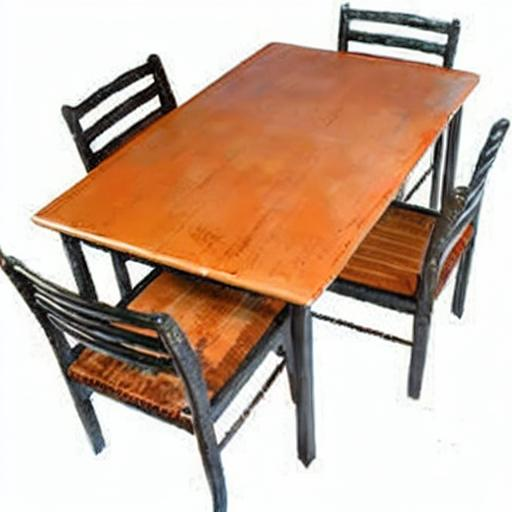

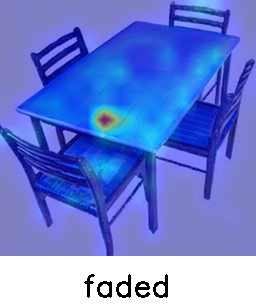

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

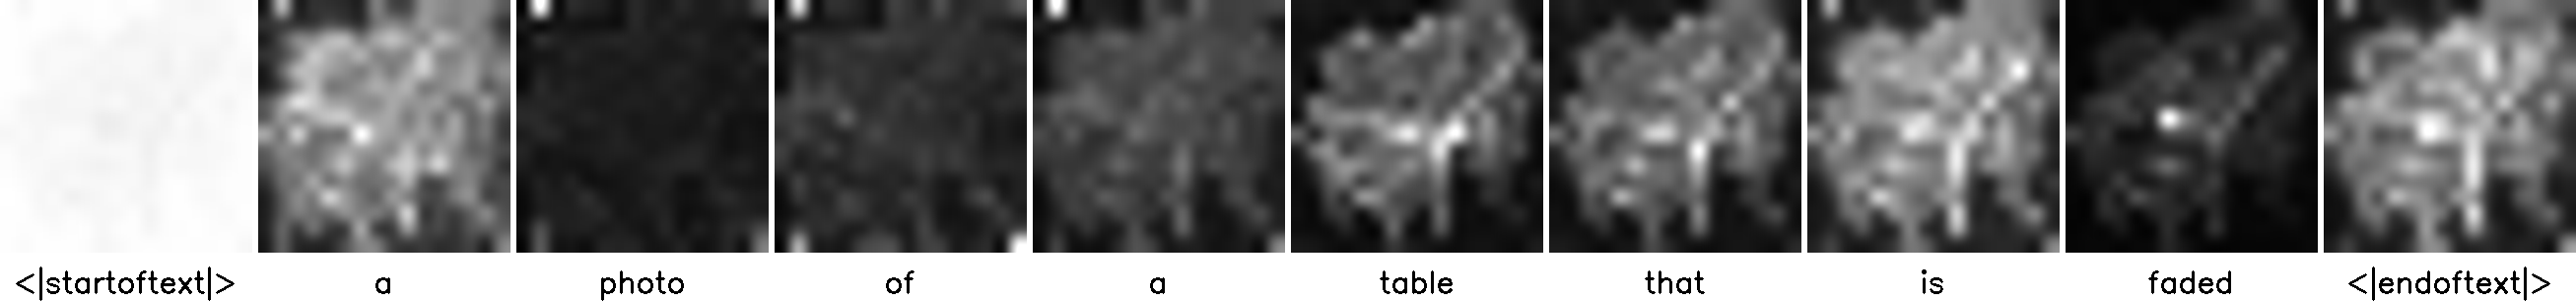

In [ ]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))

In [ ]:
from PIL import Image

type = "hazelnut"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = f"./example_image/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

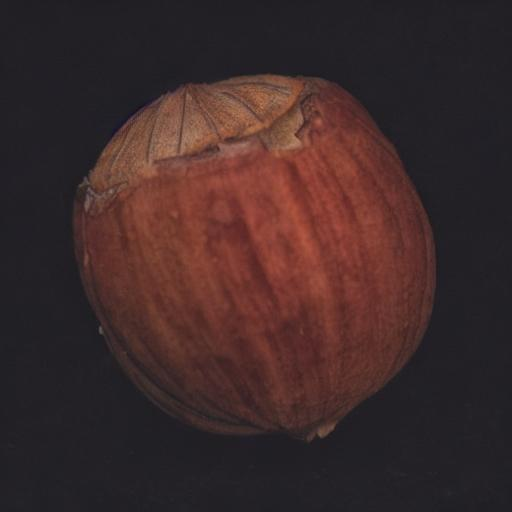

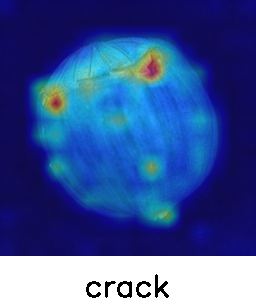

  0%|          | 0/200 [00:00<?, ?it/s]

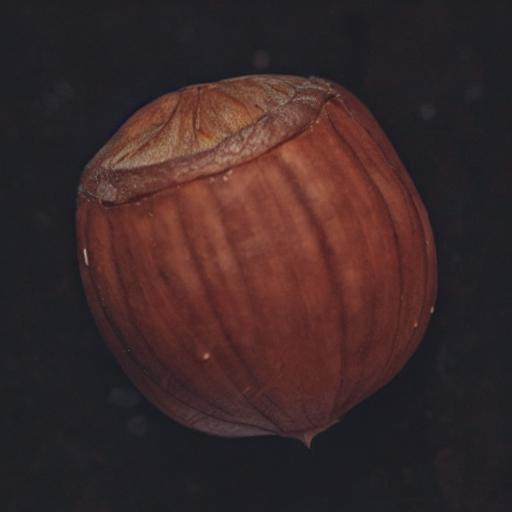

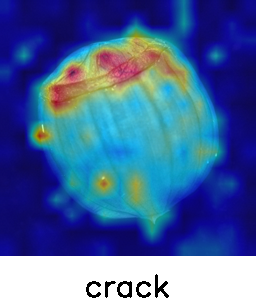

  0%|          | 0/200 [00:00<?, ?it/s]

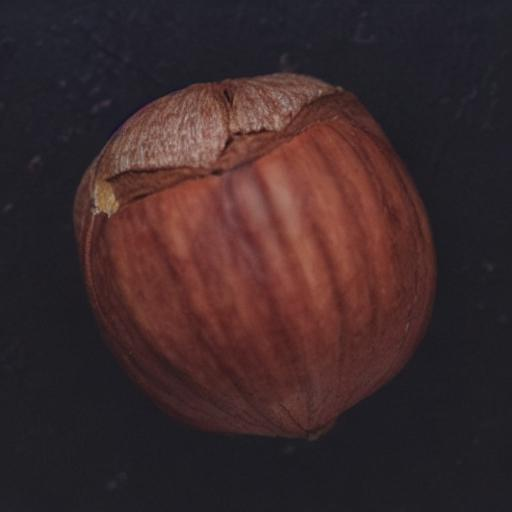

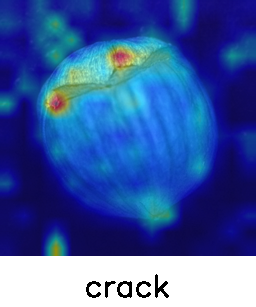

  0%|          | 0/200 [00:00<?, ?it/s]

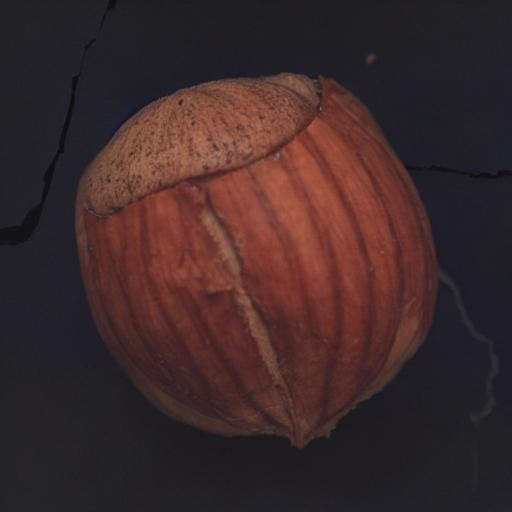

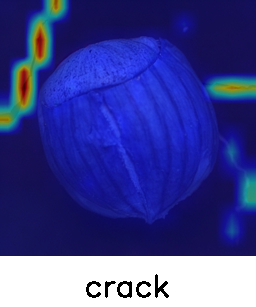

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

In [ ]:
from PIL import Image

type = "pcb"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_guidance_path = '/content/normal.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

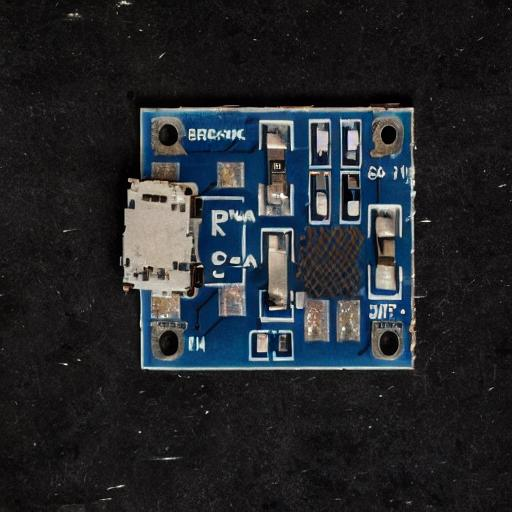

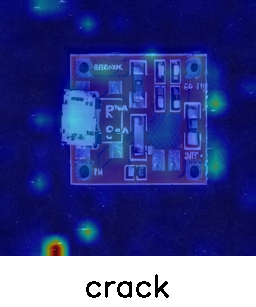

  0%|          | 0/200 [00:00<?, ?it/s]

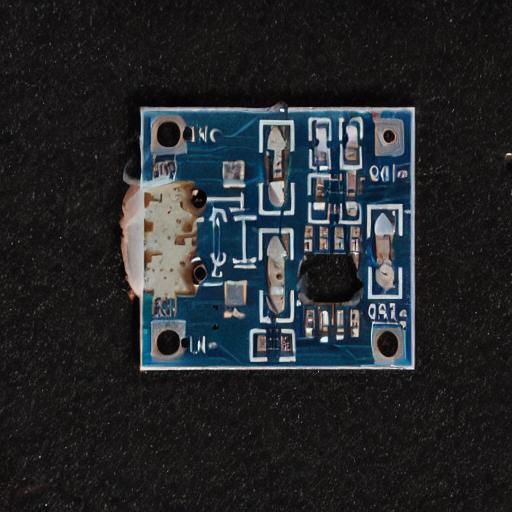

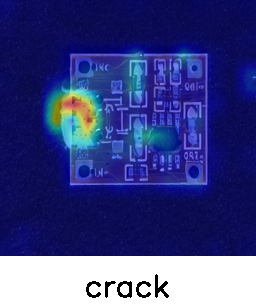

  0%|          | 0/200 [00:00<?, ?it/s]

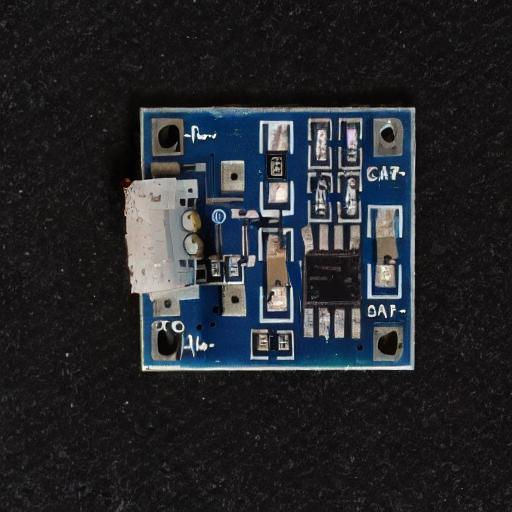

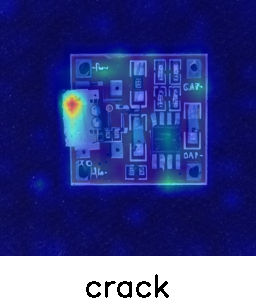

  0%|          | 0/200 [00:00<?, ?it/s]

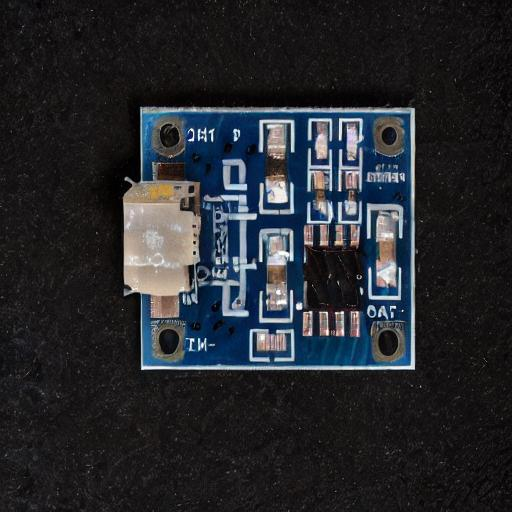

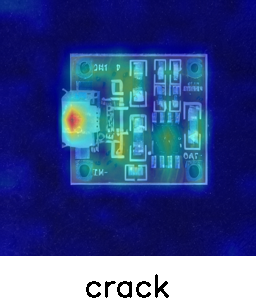

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 전체 이미지는 원본과 비슷하게 두고 결함 부분만 프롬프트와 비슷해지도록 생성해서, 같은 정상 사진에서도 프롬프트와 시드에 따라 다른 결함을 만들 수 있다.
- 기능 묘사: 탁자(색 바램), 헤이즐넛(균열), PCB(균열)에 결함을 그리고, 결함 단어가 그림의 어디에 반영됐는지 어텐션 특징 지도로 확인했다.
- 코멘트: 일단 여러 결함을 생성한 것은 좋았는데 헤이즐넛 균열과 같은 경우처럼 물체와 상관없는 배경에 금이 가게 하거나, 결함 자체의 품질이 너무 낮아 마치 예전 사람의 모습을 그대로 생성형 AI 모델에 몇십번 되돌렸을 때 형체도 없는 모습으로 바뀐 것이랑 비슷해서 별로였다.

# 추가 실험: 생성 방법 비교와 PaDiM 확인

위 실습의 PCB 예시를 그대로 써서, AnomalyAny(SD 1.5, 마스크 없이 사진 전체를 다시 그림)와 FLUX.2 [klein](마스크 안만 다시 그림)을 비교한다. AnomalyAny 결과는 위 셀이 마지막으로 만든 이미지를 그대로 쓴다.

- Test 1: 두 방법은 균열을 넣으면서 기판을 얼마나 그대로 두는가?
- Test 2: 정상 pcb4로 학습한 PaDiM은 어느 쪽을 더 불량으로 보고, 이상 맵은 균열 자리를 가리키는가?

| 항목 | 설정 |
|---|---|
| 정상 사진 | 위 실습의 normal.png (VisA pcb4 Normal/0001과 같은 사진), 768×624 |
| AnomalyAny | 위 셀의 마지막 결과 1장 (결함 단어 crack, 마스크 없음) |
| FLUX.2 [klein] | 4B distilled (4단계, guidance 1.0), IC 위 균열 모양 마스크, 문장은 위의 detailed_prompt, 시드 0, 1장 |
| Test 1 기록 | 사진 전체의 평균 변화 (0~255), FC-75 인쇄 템플릿 매칭 점수 |
| Test 2 PaDiM | 6번과 같은 설정 (Wide-ResNet50 layer2+3, 28×28, 100차원). 6번 노트북 분할의 학습용 정상 804장에서 0001을 뺀 803장으로 학습. 테스트 정상 201장과 실제 불량 100장의 점수로 기준을 잡는다 |

In [ ]:
# @title 추가 실험 준비: 비교할 이미지와 측정 함수
import gc, os, subprocess, sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

os.chdir('/content')
NORMAL = image_guidance.copy()                          # 위 PCB 예시의 정상 사진 (768×624)
ANOMALYANY = image.resize(NORMAL.size, Image.LANCZOS)   # 위 셀이 마지막으로 만든 AnomalyAny 결과
CRACK_MASK = Image.new('L', NORMAL.size, 0)             # FLUX용 균열 마스크: IC 위 대각선
ImageDraw.Draw(CRACK_MASK).line([(458, 305), (500, 332), (545, 362)], fill=255, width=12)
NORMAL.save('pcb_normal.png')
CRACK_MASK.save('pcb_crack_mask.png')

# AnomalyAny 파이프라인이 쓰던 GPU 메모리를 비운다
for _name in ['stable', 'controller']:
    globals().pop(_name, None)
gc.collect()
torch.cuda.empty_cache()

# FC-75 인쇄 템플릿 매칭 (6번 기판 라벨을 만든 방식과 같은 회전·가장자리 자르기)
_tpl = cv2.imread('/content/fc75.png', cv2.IMREAD_GRAYSCALE)
_tpl = cv2.resize(_tpl, None, fx=NORMAL.width / 1358, fy=NORMAL.width / 1358, interpolation=cv2.INTER_AREA)
FC75_TPLS = []
for _a in range(-10, 11, 2):
    _h, _w = _tpl.shape
    _r = cv2.warpAffine(_tpl, cv2.getRotationMatrix2D((_w / 2, _h / 2), _a, 1.0), (_w, _h), borderMode=cv2.BORDER_REPLICATE)
    FC75_TPLS.append(_r[int(_h * 0.1):_h - int(_h * 0.1), int(_w * 0.1):_w - int(_w * 0.1)])


def fc75_score(img):
    g = cv2.cvtColor(np.asarray(img.convert('RGB')), cv2.COLOR_RGB2GRAY)
    return max(float(cv2.matchTemplate(g, t, cv2.TM_CCOEFF_NORMED).max()) for t in FC75_TPLS)


def mean_change(img):
    a = np.asarray(img.convert('RGB').resize(NORMAL.size), dtype=np.float32)
    return float(np.abs(a - np.asarray(NORMAL, dtype=np.float32)).mean())


In [ ]:
%%writefile flux_pcb.py
# FLUX.2 [klein] 4B distilled로 마스크 안에만 균열을 그린다 (아래 셀이 별도 프로세스로 실행)
import json, sys, time
import torch
from PIL import Image
from huggingface_hub import snapshot_download
from diffusers import Flux2KleinInpaintPipeline

src, mask_path, prompt, out_path = sys.argv[1:5]
path = snapshot_download('black-forest-labs/FLUX.2-klein-4B',
                         allow_patterns=['model_index.json', 'scheduler/*', 'text_encoder/*', 'tokenizer/*', 'transformer/*', 'vae/*'])
pipe = Flux2KleinInpaintPipeline.from_pretrained(path, torch_dtype=torch.bfloat16).to('cuda')
pipe.set_progress_bar_config(disable=True)
image, mask = Image.open(src).convert('RGB'), Image.open(mask_path).convert('L')
t0 = time.time()
out = pipe(prompt=prompt, image=image, mask_image=mask, strength=1.0, num_inference_steps=4, guidance_scale=1.0,
           generator=torch.Generator('cuda').manual_seed(0)).images[0]
out.save(out_path)
print(json.dumps({'seconds': round(time.time() - t0, 1), 'size': list(out.size)}))


Writing flux_pcb.py


In [ ]:
# @title Test 1 실행: FLUX.2 [klein]으로 같은 사진에 균열 그리기
# FLUX.2 [klein]은 diffusers 0.41.0이 필요하고 위 AnomalyAny는 diffusers 0.33.1을 쓴다. 그래서 FLUX용 패키지를 따로 받아 별도 프로세스에서 돌린다.
if not os.path.isdir('/content/flux_pkgs'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--target', '/content/flux_pkgs',
                    'diffusers==0.41.0', 'transformers==5.18.0'], check=True)
res = subprocess.run([sys.executable, 'flux_pcb.py', 'pcb_normal.png', 'pcb_crack_mask.png', detailed_prompt, 'pcb_flux.png'],
                     env=dict(os.environ, PYTHONPATH='/content/flux_pkgs'), capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1] if res.returncode == 0 else res.stderr[-3000:])
FLUX_IMG = Image.open('pcb_flux.png').convert('RGB').resize(NORMAL.size)


{"seconds": 2.2, "size": [768, 624]}


       image  mean_change  fc75_score
       정상 사진         0.00       0.920
  AnomalyAny        13.34       0.441
FLUX.2 klein         2.61       0.920


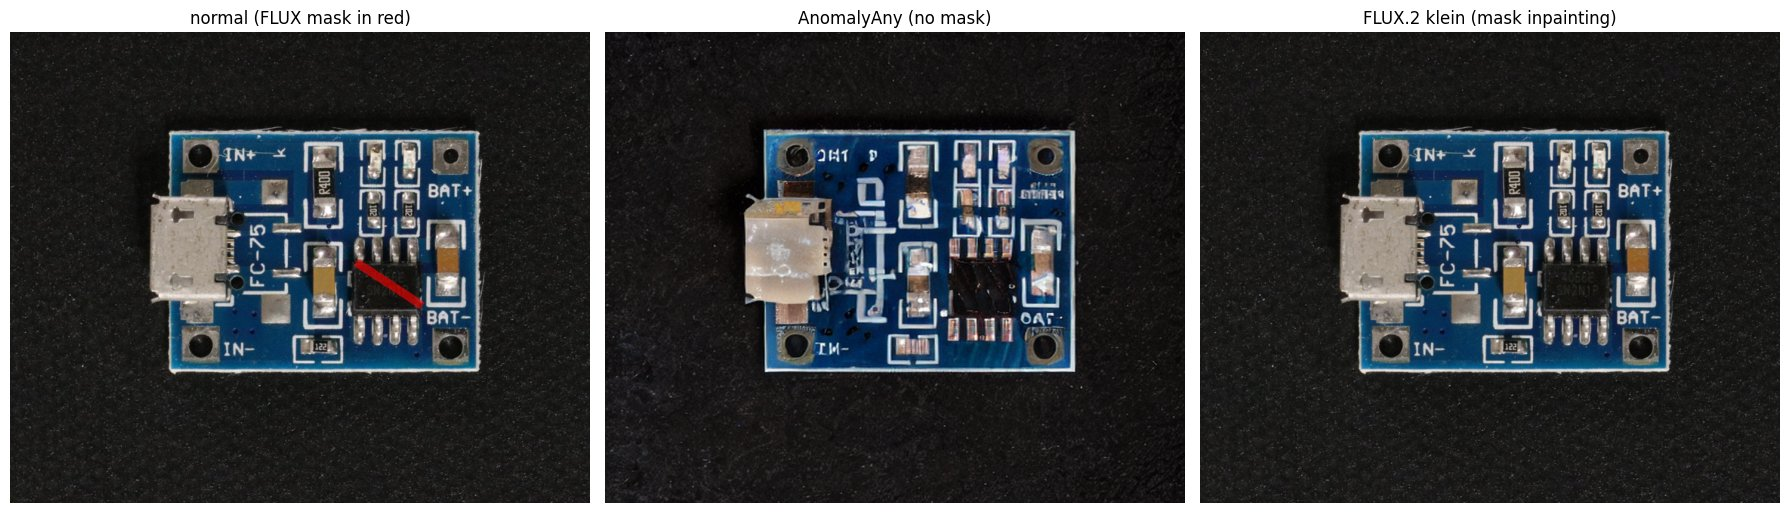

In [ ]:
# @title 표 1·그림 1. Test 1: 기판을 얼마나 그대로 두는가
T1 = pd.DataFrame([dict(image=name, mean_change=round(mean_change(img), 2), fc75_score=round(fc75_score(img), 3))
                   for name, img in [('정상 사진', NORMAL), ('AnomalyAny', ANOMALYANY), ('FLUX.2 klein', FLUX_IMG)]])
print(T1.to_string(index=False))

view = np.asarray(NORMAL, dtype=np.float32) / 255
m = np.asarray(CRACK_MASK) > 0
view[m] = view[m] * 0.4 + np.array([1.0, 0.0, 0.0]) * 0.6
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, (title, img) in zip(axes, [('normal (FLUX mask in red)', view), ('AnomalyAny (no mask)', ANOMALYANY),
                                   ('FLUX.2 klein (mask inpainting)', FLUX_IMG)]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# @title Test 2 준비: VisA pcb4 내려받기와 PaDiM 학습 (6번과 같은 설정)
import tarfile
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset

if not os.path.isdir('VisA/pcb4'):
    if not os.path.exists('VisA_20220922.tar'):
        subprocess.run(['curl', '-fsSL', '-o', 'VisA_20220922.tar',
                        'https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar'], check=True)
    with tarfile.open('VisA_20220922.tar') as tar:
        tar.extractall('VisA', members=[mm for mm in tar.getmembers() if mm.name.startswith('pcb4/')], filter='data')

anno = pd.read_csv('VisA/pcb4/image_anno.csv')
normals = anno[anno.label == 'normal'].image.tolist()
n_train = int(len(normals) * 0.8)                          # 6번 노트북 분할: CSV 순서 앞 80%
TRAIN = [p for p in normals[:n_train] if not p.endswith('Normal/0001.JPG')]   # 비교에 쓰는 정상 사진과 같은 0001은 뺀다
TEST_NORMAL, DEFECT = normals[n_train:], anno[anno.label != 'normal'].image.tolist()
print(f'학습 정상 {len(TRAIN)}장 | 테스트 정상 {len(TEST_NORMAL)}장 | 실제 불량 {len(DEFECT)}장')

NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
TF_TRAIN = T.Compose([T.Resize((256, 256)), T.RandomHorizontalFlip(0.5), T.ToTensor(), NORM])
TF_TEST = T.Compose([T.Resize((256, 256)), T.ToTensor(), NORM])


class Images(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        x = self.items[i]
        return self.tf(Image.open(f'VisA/{x}').convert('RGB') if isinstance(x, str) else x.convert('RGB'))


backbone = models.wide_resnet50_2(weights='IMAGENET1K_V1').to(device).eval()
FEATS = {}
backbone.layer2.register_forward_hook(lambda mod, inp, out: FEATS.__setitem__('l2', out))
backbone.layer3.register_forward_hook(lambda mod, inp, out: FEATS.__setitem__('l3', out))


@torch.no_grad()
def embed(x):
    backbone(x.to(device))
    f = torch.cat([F.adaptive_avg_pool2d(FEATS[k], (28, 28)) for k in ('l2', 'l3')], 1)
    return f.permute(0, 2, 3, 1).reshape(x.size(0), 28 * 28, -1)


torch.manual_seed(0)
emb = torch.cat([embed(x) for x in DataLoader(Images(TRAIN, TF_TRAIN), batch_size=16, shuffle=True, num_workers=2)])
PROJ = F.normalize(torch.randn(emb.shape[-1], 100, device=device), dim=0)   # 무작위 투영 1,536 → 100차원
emb = emb @ PROJ
MEAN = emb.mean(0)
centered = emb - MEAN
COV = torch.einsum('npi,npj->pij', centered, centered) / (emb.shape[0] - 1) + 1e-4 * torch.eye(100, device=device)
INV_COV = torch.linalg.inv(COV.cpu()).to(device)   # GPU 배치 역행렬이 이 환경에서 cuBLAS 오류를 내서 CPU에서 계산
del emb, centered
torch.cuda.empty_cache()


@torch.no_grad()
def padim(items):
    maps = []
    for x in DataLoader(Images(items, TF_TEST), batch_size=32, num_workers=2):
        d = embed(x) @ PROJ - MEAN
        maps.append((torch.einsum('bpi,pij->bpj', d, INV_COV) * d).sum(-1).clamp_min(0).sqrt().reshape(-1, 28, 28).cpu().numpy())
    maps = np.concatenate(maps)
    return maps.reshape(len(maps), -1).max(1), maps


S_NORMAL, _ = padim(TEST_NORMAL)
S_DEFECT, _ = padim(DEFECT)
THR = np.sort(S_DEFECT)[int(len(S_DEFECT) * 0.10)]          # 실제 불량 90%를 잡는 기준선 (6번 Test 1과 같은 정의)
print(f'테스트 정상 점수 중앙값 {np.median(S_NORMAL):.2f} | 실제 불량 중앙값 {np.median(S_DEFECT):.2f} | 불량 90% 기준선 {THR:.2f}')


학습 정상 803장 | 테스트 정상 201장 | 실제 불량 100장


테스트 정상 점수 중앙값 17.76 | 실제 불량 중앙값 27.37 | 불량 90% 기준선 22.67


       image  padim_score  above_test_normals_pct  defect_by_threshold  max_in_crack_mask
       정상 사진        17.33                    45.3                False              False
  AnomalyAny        34.73                    99.5                 True              False
FLUX.2 klein        17.40                    46.8                False              False


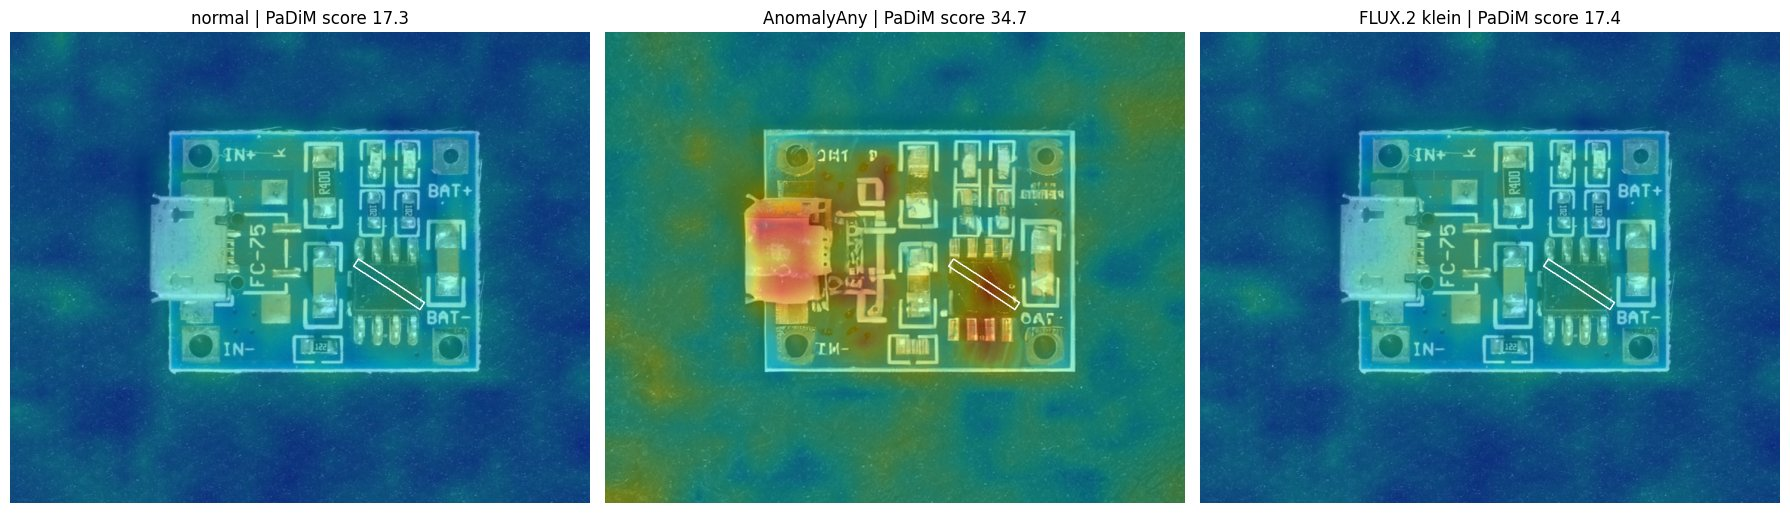

In [ ]:
# @title 표 2·그림 2. Test 2: PaDiM이 보는 이상 정도와 위치
names = ['정상 사진', 'AnomalyAny', 'FLUX.2 klein']
imgs = [NORMAL, ANOMALYANY, FLUX_IMG]
scores, maps = padim(imgs)
near_mask = F.max_pool2d(torch.from_numpy((np.asarray(CRACK_MASK.resize((28, 28), Image.BOX)) > 0).astype(np.float32))[None, None],
                         3, stride=1, padding=1)[0, 0].numpy() > 0    # 균열 마스크와 겹치는 칸 + 주변 1칸
T2 = pd.DataFrame(dict(image=names, padim_score=scores.round(2),
                       above_test_normals_pct=[round(float((S_NORMAL < s).mean() * 100), 1) for s in scores],
                       defect_by_threshold=scores >= THR,
                       max_in_crack_mask=[bool(near_mask.flat[mp.argmax()]) for mp in maps]))
print(T2.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
vmax = max(float(mp.max()) for mp in maps)
for ax, name, img, mp, s in zip(axes, ['normal', 'AnomalyAny', 'FLUX.2 klein'], imgs, maps, scores):
    heat = np.asarray(Image.fromarray(mp.astype(np.float32)).resize(img.size, Image.BILINEAR))
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=vmax)
    ax.contour(np.asarray(CRACK_MASK) > 0, levels=[0.5], colors='white', linewidths=1)
    ax.set_title(f'{name} | PaDiM score {s:.1f}')
    ax.axis('off')
plt.tight_layout()
plt.show()


### Test 1 정리

- 실험 내용: 위 AnomalyAny 결과에서 PCB가 깨지고 전체적인 생성 품질도 별로 같아서, 같은 정상 사진과 균열 문장으로 FLUX.2에 마스크를 주고 그려 기판이 얼마나 그대로 남는지 비교해 보았다.
- 결과: AnomalyAny는 사진 전체가 바뀌어 FC-75 인쇄가 사라졌고, USB 단자와 글자도 망가졌다. FLUX는 기판이 그대로였지만 얇은 균열 마스크 안에 균열이 거의 그려지지 않았다.
- 분석: 똑같은 환경에서 전체와 바뀌는 AnomalyAny보다는 그대로 깔끔하지만 너무 그대로라 변한게 없어 아쉬웠다.

### Test 2 정리

- 실험 내용: 생성한 결함이 정말 불량처럼 보이는지, 6번에서 쓴 PaDiM에 정상 사진, AnomalyAny 결과, FLUX 결과를 넣어 어느 쪽을 더 불량으로 보는지 확인해 보았다.
- 결과: AnomalyAny는 점수 34.7로 테스트 정상의 99.5%보다 높아 불량 기준선을 넘었고, 이상 맵은 USB 단자 쪽이 가장 높았다. FLUX는 17.4로 정상 사진과 거의 같아 불량으로 보지 않았다.
- 분석: FLUX 모델이 생성한 불량을 불량으로 보지 않은 이유는 불량 생성을 안하고 그대로 기판을 유지해서 낸 모델 문제라고 생각한다.

## 개인 회고

### KPT
- Keep: 새 모델(FLUX)을 쓸 때 원본 실습과 같은 프롬프트·이미지·마스크로 비교해서 차이를 바로 볼 수 있었다. 다음에도 모델을 비교할 때는 조건을 같게 맞춰 볼 것이다.
- Problem: 스테이블 디퓨전은 시드를 고정하지 않아서 이전 실험에서 같은 코드인데도 말이 나왔다 안 나왔다 해서, 한 장만으로 비교하기는 어려웠고, AnomalyAny는 결함을 넣으면서 기판 전체를 다시 그려 FC-75 인쇄가 사라졌고, PaDiM이 불량이라고 본 것도 균열보다는 망가진 USB 단자 때문이었다. FLUX는 기판은 그대로 뒀지만 같은 문장으로는 아무리 마스크를 넖혀도 마스크 안에 균열을 그리지 않았다.
- Try: 모델을 비교할 때는 시드를 고정해서 진행 할 것이고, 인페인팅을 할 때는 사진 전체 설명 대신 마스크 안에 그릴 결함을 문장으로 적어서 다시 생성해 볼 것이고, 생성 결과는 점수만 보지 않고 이상 맵 위치와 사진을 같이 확인할 것이다.

### AAR
- 목표: 생성형 AI로 제조 결함 데이터를 만드는 실습을 해 보고, 최신 모델인 FLUX.2와 비교해 기판을 지키면서 결함을 넣을 수 있는지 확인한다.
- 결과: FLUX는 프롬프트를 잘 따랐고(말 탄 우주인, 보물 상자) 마스크 밖도 SD보다 덜 바꿨으며, distilled는 base보다 몇십배 빨랐다. AnomalyAny는 기판 전체가 바뀌어 인쇄가 사라졌고, FLUX는 기판은 그대로였지만 균열이 그려지지 않아 PaDiM도 정상으로 봤다.
- 차이 원인: 요번에 사용된 스테이블 디퓨전이 오래된 모델이라 문장을 덜 따랐고, 시드를 정하지 않아 결과가 매번 달랐다. AnomalyAny는 마스크 없이 사진 전체를 다시 그리는 방식이라 기판이 망가졌다. FLUX 인페인팅은 마스크 안을 문장대로 다시 그리는데, AnomalyAny와 같은 사진 전체 설명 문장을 써서 마스크 안을 원래 IC로 채웠다.
- 다음 액션: FLUX에 결함만 설명하는 문장과 실제 결함 사진을 줘서 다시 생성하고, 만든 결함으로 이상 탐지 모델을 학습·평가해 쓸모를 확인한다.